In [24]:
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow
assert pyarrow  # enables pandas parquet support

from pathlib import Path

PICKUP, DROPOFF = "tpep_pickup_datetime", "tpep_dropoff_datetime"
COLUMNS = [PICKUP, DROPOFF, "trip_distance", "PULocationID", "DOLocationID"]
DISTANCE_THRESHOLD = 40
INVALID_ZONE_START = 264

#Helper functions
def read_columns(path):
    return pd.read_parquet(path, columns=COLUMNS)

# This is need to make the files agnostic of the project root name as I don't know if we all have it as CodingChallenge.
# Find the project root by walking up from the current working directory
# until we see the data folder. Works regardless of where Jupyter was launched.
def find_project_root(marker="OriginalData_DoNotDelete", start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"Could not find '{marker}' above {start}")

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "OriginalData_DoNotDelete" / "yellow_tripdata_2026-Jan.parquet"
CLEANED_DIR = PROJECT_ROOT / "CleanedData"

In [25]:
dataframe = read_columns(DATA_PATH)
print(f"Number of lines in data: {len(dataframe)}")

Number of lines in data: 3724889


In [26]:
def plot_distance_distribution(dataframe_original, dataframe_clean=None, threshold=DISTANCE_THRESHOLD,
                               bins=200, clip_max=60, log_y=False, title=None):
    """
    Plot the distribution of trip_distance for the raw dataframe
    and (optionally) the cleaned dataframe.

    Parameters
    ----------
    dataframe_original : DataFrame   — the raw data (must contain 'trip_distance')
    dataframe_clean : DataFrame — optional cleaned data for side-by-side comparison
    bins : int           — number of histogram bins
    clip_max : float     — x-axis upper limit (keeps long tails readable)
    log_y : bool         — log-scale y-axis (useful when N is large / skewed)
    title : str          — optional plot title
    """
    # --- stats on the raw data (before any clipping) ---
    raw = dataframe_original["trip_distance"].dropna()
    raw_stats = {
        "n": len(raw),
        "mean": raw.mean(),
        "median": raw.median(),
        "p90": raw.quantile(0.90),
        "p99": raw.quantile(0.99),
        "max": raw.max(),
    }

    fig, axes = plt.subplots(1, 2 if dataframe_clean is not None else 1,
                             figsize=(14, 5), squeeze=False)
    axes = axes[0]

    # ---- panel 1: raw ----
    ax = axes[0]
    ax.hist(raw[raw <= clip_max], bins=bins, color="tab:blue", alpha=0.85)
    ax.axvline(threshold, color="tab:red", linestyle="--",
               label=f"threshold = {threshold}")
    ax.set_title("Raw trip_distance distribution")
    ax.set_xlabel("trip_distance (miles)")
    ax.set_ylabel("trips" + (" (log)" if log_y else ""))
    ax.legend()
    if log_y:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)

    # ---- panel 2: cleaned (optional) ----
    if dataframe_clean is not None:
        clean = dataframe_clean["trip_distance"].dropna()
        ax = axes[1]
        ax.hist(clean[clean <= clip_max], bins=bins, color="tab:green", alpha=0.85)
        ax.set_title("Cleaned trip_distance distribution")
        ax.set_xlabel("trip_distance (miles)")
        ax.set_ylabel("trips" + (" (log)" if log_y else ""))
        ax.grid(alpha=0.3)
        if log_y:
            ax.set_yscale("log")

        # annotate drop rate
        kept = len(clean) / len(raw) if len(raw) else 0
        ax.text(0.98, 0.95,
                f"kept {kept:.1%} of rows\n({len(clean):,} / {len(raw):,})",
                transform=ax.transAxes, ha="right", va="top",
                bbox=dict(boxstyle="round", fc="white", ec="gray"))

    # ---- overall title with raw stats ----
    stat_line = (
        f"n={raw_stats['n']:,}  |  mean={raw_stats['mean']:.2f}  "
        f"median={raw_stats['median']:.2f}  "
        f"p90={raw_stats['p90']:.2f}  p99={raw_stats['p99']:.2f}  "
        f"max={raw_stats['max']:.1f}"
    )
    fig.suptitle(title or f"Trip distance distribution — {stat_line}",
                 fontsize=11)
    fig.tight_layout()
    return fig, raw_stats

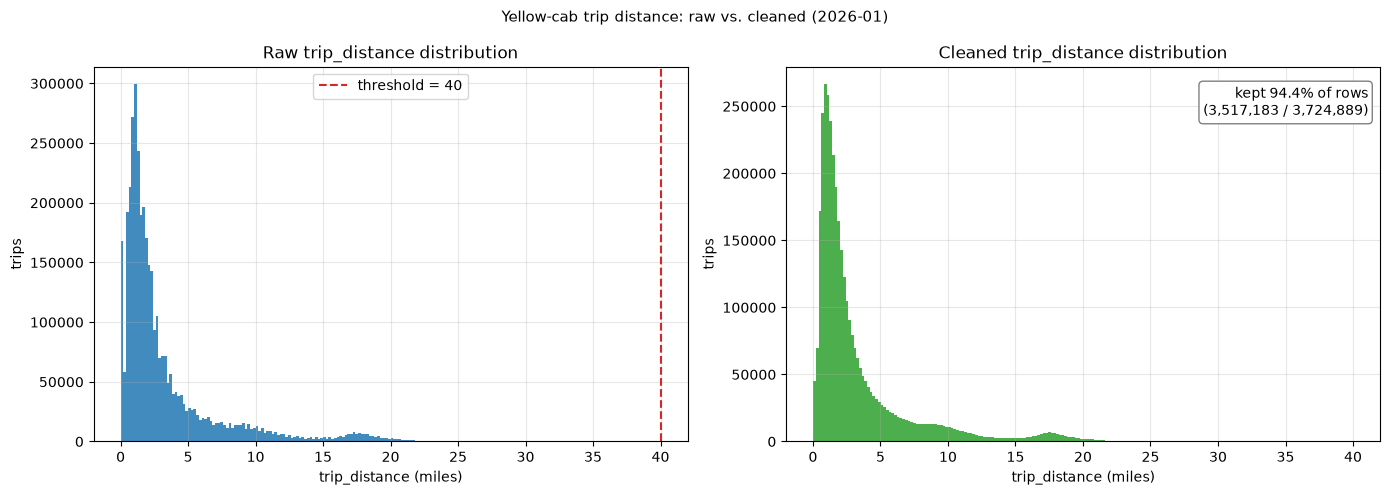

Raw distance stats:
        n: 3,724,889.00
     mean: 6.46
   median: 1.81
      p90: 8.56
      p99: 19.54
      max: 269,097.48


In [27]:
# Load raw data (already done in your notebook: dataframe = read_columns(...))
dataframe_clean = read_columns(CLEANED_DIR / "yellow_tripdata_2026-Jan_Cleaned-Dur-Dis-Zone264-265.parquet")

fig, stats = plot_distance_distribution(
    dataframe,
    dataframe_clean,
    threshold=DISTANCE_THRESHOLD,
    bins=200,
    clip_max=40,      # >40 is filtered out, so 60 lets you see the cliff at 40
    log_y=False,       # taxi distances are heavily right-skewed
    title="Yellow-cab trip distance: raw vs. cleaned (2026-01)"
)
plt.show()

print("Raw distance stats:")
for k, v in stats.items():
    print(f"  {k:>7}: {v:,.2f}")

In [28]:
trip_duration = dataframe["trip_distance"]
print(f"NaN: {trip_duration.isna().sum():>8,}")
print(f"<= 0: {(trip_duration <= 0).sum():>8,}")
print(f"> 40: {(trip_duration > 40).sum():>8,}")
print(f"total bad: {(trip_duration.isna() | (trip_duration <= 0) | (trip_duration > 40)).sum():>8,}")

NaN:        0
<= 0:  125,738
> 40:    1,281
total bad:  127,019


In [29]:
def plot_duration_distribution(df_raw, df_clean=None, threshold=120,
                               bins=200, clip_max=120, log_y=False, title=None):
    """
    Plot the distribution of trip duration (in minutes) for the raw dataframe
    and (optionally) the cleaned dataframe.
    """
    # 1. Ensure the raw dataframe has a duration column (calculate it on the fly if missing)
    if "duration_min" not in df_raw.columns:
        raw_durations = (df_raw["tpep_dropoff_datetime"] - df_raw["tpep_pickup_datetime"]).dt.total_seconds() / 60
    else:
        raw_durations = df_raw["duration_min"]

    raw = raw_durations.dropna()

    # --- stats on the raw data (before any clipping) ---
    raw_stats = {
        "n": len(raw),
        "mean": raw.mean(),
        "median": raw.median(),
        "p90": raw.quantile(0.90),
        "p99": raw.quantile(0.99),
        "max": raw.max(),
    }

    fig, axes = plt.subplots(1, 2 if df_clean is not None else 1,
                             figsize=(14, 5), squeeze=False)
    axes = axes[0]

    # ---- panel 1: raw ----
    ax = axes[0]
    ax.hist(raw[raw <= clip_max], bins=bins, color="tab:blue", alpha=0.85)
    ax.axvline(threshold, color="tab:red", linestyle="--",
               label=f"threshold = {threshold}")
    ax.set_title("Raw duration distribution")
    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("trips" + (" (log)" if log_y else ""))
    ax.legend()
    if log_y:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)

    # ---- panel 2: cleaned (optional) ----
    if df_clean is not None:
        # The cleaned dataframe should already have duration_min, but just in case:
        if "duration_min" not in df_clean.columns:
             clean = ((df_clean["tpep_dropoff_datetime"] - df_clean["tpep_pickup_datetime"]).dt.total_seconds() / 60).dropna()
        else:
             clean = df_clean["duration_min"].dropna()

        ax = axes[1]
        ax.hist(clean[clean <= clip_max], bins=bins, color="tab:green", alpha=0.85)
        ax.set_title("Cleaned duration distribution")
        ax.set_xlabel("Duration (minutes)")
        ax.set_ylabel("trips" + (" (log)" if log_y else ""))
        ax.grid(alpha=0.3)
        if log_y:
            ax.set_yscale("log")

        # annotate drop rate
        kept = len(clean) / len(raw) if len(raw) else 0
        ax.text(0.98, 0.95,
                f"kept {kept:.1%} of rows\n({len(clean):,} / {len(raw):,})",
                transform=ax.transAxes, ha="right", va="top",
                bbox=dict(boxstyle="round", fc="white", ec="gray"))

    # ---- overall title with raw stats ----
    stat_line = (
        f"n={raw_stats['n']:,}  |  mean={raw_stats['mean']:.2f}  "
        f"median={raw_stats['median']:.2f}  "
        f"p90={raw_stats['p90']:.2f}  p99={raw_stats['p99']:.2f}  "
        f"max={raw_stats['max']:.1f}"
    )
    fig.suptitle(title or f"Trip duration distribution — {stat_line}", fontsize=11)
    fig.tight_layout()
    return fig, raw_stats

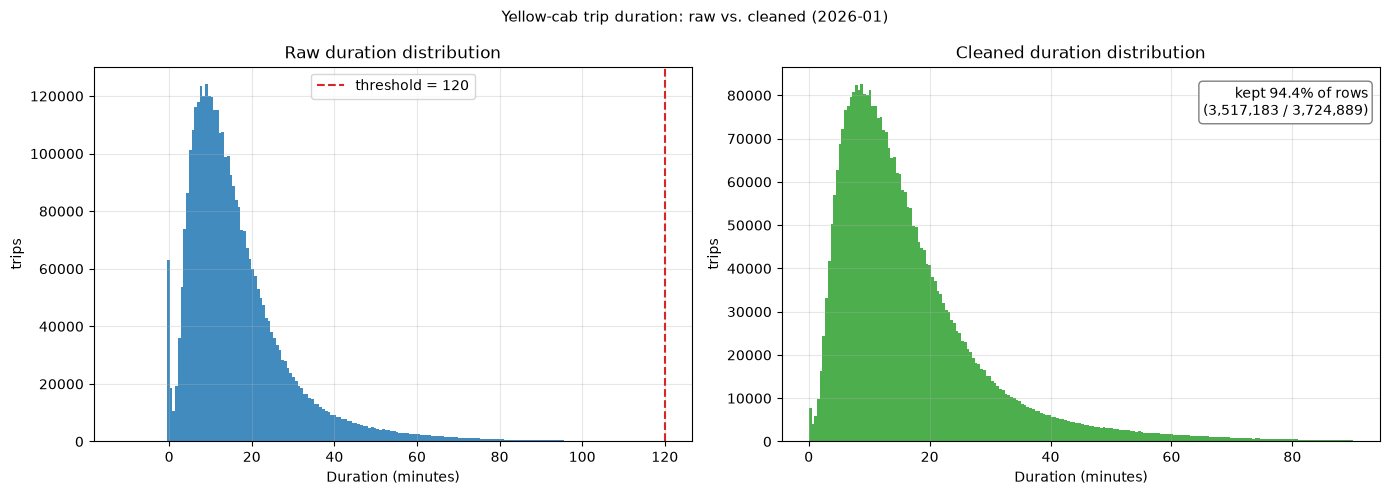

Raw duration stats (minutes):
        n: 3,724,889.00
     mean: 17.19
   median: 13.37
      p90: 32.25
      p99: 71.43
      max: 7,507.90


In [30]:
# Assuming `dataframe` is your raw data and `dataframe_clean` is loaded from parquet
fig, stats = plot_duration_distribution(
    dataframe,                 # Raw data (function calculates duration on the fly)
    dataframe_clean,           # Cleaned data (already has duration_min)
    threshold=120,             # Your max duration filter is 120 mins
    bins=200,
    clip_max=120,              # Zoom in on the 0-120 minute range
    log_y=False,               # Linear scale for readability
    title="Yellow-cab trip duration: raw vs. cleaned (2026-01)"
)
plt.show()

print("Raw duration stats (minutes):")
for k, v in stats.items():
    print(f"  {k:>7}: {v:,.2f}")

In [31]:
# Calculate duration on the fly from the raw dataframe
trip_duration = (
    dataframe["tpep_dropoff_datetime"] - dataframe["tpep_pickup_datetime"]
).dt.total_seconds() / 60

print(f"NaN: {trip_duration.isna().sum():>8,}")
print(f"<= 0: {(trip_duration <= 0).sum():>8,}")
print(f"> 90: {(trip_duration > 90).sum():>8,}")
print(f"total bad: {(trip_duration.isna() | (trip_duration <= 0) | (trip_duration > 90)).sum():>8,}")

NaN:        0
<= 0:   45,070
> 90:   15,079
total bad:   60,149


# 1. Trip Duration: Cutoff at 90 Minutes

**Decision:** Keep trips with a duration strictly greater than 0 minutes and less than or equal to 90 minutes (`(0, 90]`).

![TripDurationDistribution](Images/Duration.png)

## The Evidence
- Total Rows: 3,724,889
- Median: 13.37 minutes
- 90th Percentile (p90): 32.25 minutes
- 99th Percentile (p99): 71.43 minutes
- Max: 7,507.90 minutes (~5.2 days)

## Breakdown of Removed Data
- NaN: 0
- <= 0: 45,070 rows
- `> 90`: 15,079 rows
- Total Dropped: 60,149 rows (1.61% of the dataset)

## Rationale
1. **The Upper Bound (90 minutes):** While 99% of trips (p99) are under 72 minutes, a cutoff of 90 minutes allows for legitimate trips in heavy traffic. By cutting at 90 minutes instead of the original 120 minutes, we remove only 15,079. Because the model uses Root Mean Squared Error (RMSE), these extreme outliers would disproportionately penalise the model and distort predictions for normal trips.
2. **The Lower Bound (> 0 minutes):** Similar to distance, there is a large cluster of 45,070 trips where the drop off time was identical to or earlier than the pickup time. These are invalid metering events and must be removed.
3. **Model Efficiency:** Cutting at 90 minutes retains 98.4% of the valid duration data, focusing the model on the predictable "body" of the distribution while safely jettisoning the "forgotten meter" anomalies.

---

# 2. Trip Distance: Cutoff at 40 Miles

**Decision:** Keep trips with a distance strictly greater than 0 miles and less than or equal to 40 miles (`(0, 40]`).

![Trip Distance Distribution](Images/Distance.png)

## The Evidence
- Total Rows: 3,724,889
- Median: 1.81 miles
- 90th Percentile (p90): 8.56 miles
- 99th Percentile (p99): 19.54 miles
- Max: 269,097.48 miles

## Breakdown of Removed Data
- NaN: 0 (The dataset is pre-cleaned for missing values by the publisher)
- <= 0: 125,738 rows
- `> 40`: 1,281 rows
- Total Dropped: 127,019 rows (3.41% of the dataset)

## Rationale
1. **The Upper Bound (40 miles):** The 99th percentile is 19.54 miles, meaning 99% of all trips in NYC are under 20 miles. A cutoff at 40 miles trims only 1,281 rows (0.03% of the data). However, it successfully removes the physically impossible maximum value of 269,097 miles (likely a GPS/meter error). A cutoff of 40 miles ensures we remove noise and corruption without losing legitimate long trips.
2. **The Lower Bound (> 0 miles):** The plot shows a massive spike at 0 miles. These 125,738 rows represent cancelled trips, meter errors, or immediate drop-offs. Removing them is necessary to prevent the model from learning that a trip can take time but cover zero distance.
3. **Visual Proof (The Histograms):**
   - The distance plot shows a massive spike at 0 miles (removed by the lower bound) and confirms that the bulk of the data is clustered under 10 miles.
   - The red threshold line at 40 miles sits far out in the tail, visually confirming that we are trimming the extreme edge without touching the core distribution.

---

# Summary of Impact

| Filter | Total Dropped | % of Data | Primary Cause of Drop | Goal Achieved |
| :--- | :--- | :--- | :--- | :--- |
| **Distance (0, 40]** | 127,019 | 3.41% | Zero-distance trips (125k) | Removes meter errors; trims max outlier of 269k miles. |
| **Duration (0, 90]** | 60,149 | 1.61% | Zero-time trips (45k) | Removes forgotten meters (max 5.2 days); limits RMSE penalty. |

By implementing these cutoffs, the cleaning pipeline removes approximately **5% of the raw dataset**. This 5% is almost entirely composed of physically impossible data, cancelled trips, and extreme noise.